# 01 · Dados brutos (ANA/SGB)

**Objetivo:** carregar os exports das estações, conferir formato, unidades, fuso e lacunas, e salvar um painel **horário**.

**Como colocar os dados:** exporte do Hidrotelemetria/HidroWeb e salve em `data/raw/ana/` com o **código da estação no início do nome**
(ex.: `86510000_2015-2019.csv`, `86510000_2020-2025.csv`). Vários arquivos da mesma estação são concatenados automaticamente.
Estações: ver `src/config.py` (`STATIONS`). Se não houver nenhum arquivo, o notebook usa dados **sintéticos** só para testar o código.

In [1]:
import os, sys
sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, data, features, metrics, pipeline
plt.rcParams["figure.figsize"] = (11, 3.4)
plt.rcParams["axes.grid"] = True

In [2]:
ANA_DIR = config.ANA_DIR
arquivos = data.list_exports(ANA_DIR)
print(f"{len(arquivos)} arquivo(s) em {ANA_DIR}")
for a in arquivos[:30]:
    print(" -", a.name)

USAR_SINTETICO = len(arquivos) == 0
if USAR_SINTETICO:
    from src.synthetic import write_synthetic_exports
    ANA_DIR = config.RAW / "ana_SINTETICO"
    write_synthetic_exports(ANA_DIR)
    print("\nATENÇÃO: sem dados reais. Usando dados SINTÉTICOS apenas para testar o pipeline.")
    print("NÃO use resultados desta execução no artigo.")

4 arquivo(s) em /home/beckm/projetos/capstone/data/raw/ana
 - 86472000_telemetrica_api.csv
 - 86472600_telemetrica_api.csv
 - 86510000_telemetrica_api.csv
 - 86720000_telemetrica_api.csv


## 1. Formato real do export
Olhe as colunas: o leitor tenta achar data/hora, cota (nível) e chuva sozinho. Se ele errar, o erro mostra as colunas; ajuste `src/data.py` (`_parse_datetime` / `_find_col`).

In [3]:
primeiro = data.list_exports(ANA_DIR)[0]
bruto = data.read_table(primeiro)
print(primeiro.name, bruto.shape)
print(list(bruto.columns))
display(bruto.head())

86472000_telemetrica_api.csv (313267, 7)
['Data_Hora_Medicao', 'Cota_Adotada', 'Cota_Adotada_Status', 'Chuva_Adotada', 'Chuva_Adotada_Status', 'Vazao_Adotada', 'Vazao_Adotada_Status']


,Data_Hora_Medicao,Cota_Adotada,Cota_Adotada_Status,Chuva_Adotada,Chuva_Adotada_Status,Vazao_Adotada,Vazao_Adotada_Status
0,2015-09-14 12:45:00,401.0,1.0,NaN,NaN,334.2,1.0
1,2015-09-14 13:45:00,400.0,1.0,0.0,0.0,332.0,1.0
2,2015-09-14 14:45:00,400.0,0.0,0.0,0.0,332.0,0.0
3,2015-09-14 15:45:00,400.0,0.0,0.0,0.0,332.0,0.0
4,2015-09-14 16:45:00,399.0,0.0,0.0,0.0,329.8,0.0


## 2. Carregar cada estação

In [4]:
series = {}
for cod, info in config.STATIONS.items():
    try:
        s = data.load_station(cod, raw_dir=ANA_DIR)
    except FileNotFoundError:
        print("SEM ARQUIVO:", cod, info["nome"])
        continue
    series[cod] = s
    passo = s.index.to_series().diff().median()
    cmax = s["cota_cm"].max() if "cota_cm" in s else None
    print(f"{cod} {info['nome']:<18} {s.index.min()} -> {s.index.max()} | passo típico {passo} | colunas {list(s.columns)} | cota máx {cmax}")

86472000 Linha José Júlio   2015-09-14 12:45:00 -> 2026-06-08 23:45:00 | passo típico 0 days 00:15:00 | colunas ['cota_cm', 'chuva_mm'] | cota máx 6274.0


86472600 Santa Tereza       2023-09-30 20:00:00 -> 2026-06-08 23:45:00 | passo típico 0 days 00:15:00 | colunas ['cota_cm', 'chuva_mm'] | cota máx 2233.0


86510000 Muçum              2018-04-30 00:00:00 -> 2026-06-08 23:45:00 | passo típico 0 days 00:15:00 | colunas ['cota_cm', 'chuva_mm'] | cota máx 2557.0


86720000 Encantado          2014-12-03 00:00:00 -> 2026-06-06 23:45:00 | passo típico 0 days 00:15:00 | colunas ['cota_cm', 'chuva_mm'] | cota máx 2073.0


**Confira agora (isso evita semanas de erro depois):**
1. **Unidade da cota:** se o máximo for algo como 20–30 (e não 2000–3000), está em metros → `COTA_SCALE = 100` em `config.py`.
2. **Fuso:** compare o horário do pico de uma cheia conhecida com o boletim do SGB. Se estiver em UTC, `UTC_OFFSET_HOURS = -3`.
3. **Chuva:** confirme se cada leitura é mm no intervalo (soma) ou acumulado (nesse caso, é preciso diferenciar).

## 3. Painel horário e cobertura

In [5]:
panel = data.build_panel(raw_dir=ANA_DIR)
panel = data.fill_short_gaps(panel, max_gap=3)
cobertura = data.coverage_report(panel)
display(cobertura)

,primeiro,ultimo,% válido,maior lacuna (h)
coluna,,,,
cota_86472000,2015-09-14 12:00:00,2026-06-08 23:00:00,65.7,7133
chuva_86472000,2015-09-14 13:00:00,2026-06-08 23:00:00,73.1,7131
cota_86472600,2023-10-01 00:00:00,2026-06-08 23:00:00,23.0,77376
chuva_86472600,2023-10-01 00:00:00,2026-06-08 23:00:00,22.8,77376
cota_86510000,2018-04-30 01:00:00,2026-06-08 23:00:00,68.7,29857
chuva_86510000,2018-04-30 01:00:00,2026-06-08 23:00:00,69.0,29857
cota_86720000,2014-12-03 05:00:00,2026-06-06 23:00:00,67.2,13365
chuva_86720000,2014-12-03 01:00:00,2026-06-06 23:00:00,75.2,13364


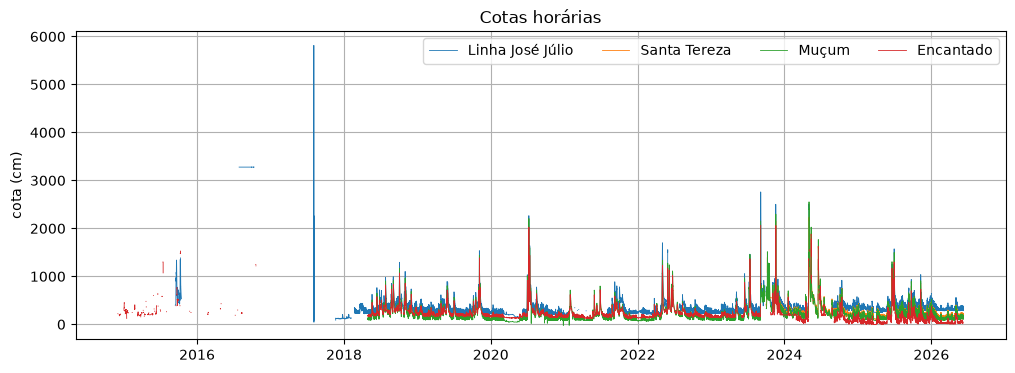

In [6]:
cota_cols = [c for c in panel.columns if c.startswith("cota_")]
fig, ax = plt.subplots(figsize=(12, 4))
for c in cota_cols:
    nome = config.STATIONS[c.split("_")[1]]["nome"]
    ax.plot(panel.index, panel[c], lw=0.6, label=nome)
ax.set_ylabel("cota (cm)"); ax.legend(ncol=4); ax.set_title("Cotas horárias")
plt.show()

## 4. Os eventos extremos estão nos dados?

In [7]:
for nome, (ini, fim) in config.EVENTS.items():
    cols = [f"cota_{c}" for c in config.TARGETS if f"cota_{c}" in panel]
    trecho = panel.loc[ini:fim, cols]
    print(nome, "| cota máx (cm):", trecho.max().round(0).to_dict(), "| horas com dado:", trecho.notna().sum().to_dict())

set/2023 | cota máx (cm): {'cota_86510000': 2149.0, 'cota_86720000': 2062.0} | horas com dado: {'cota_86510000': 198, 'cota_86720000': 85}
nov/2023 | cota máx (cm): {'cota_86510000': 2298.0, 'cota_86720000': 2059.0} | horas com dado: {'cota_86510000': 384, 'cota_86720000': 384}
mai/2024 | cota máx (cm): {'cota_86510000': 2552.0, 'cota_86720000': 1873.0} | horas com dado: {'cota_86510000': 456, 'cota_86720000': 169}


In [8]:
panel.to_parquet(config.PROCESSED / "panel_hourly.parquet")
print("salvo:", config.PROCESSED / "panel_hourly.parquet", panel.shape)

salvo: /home/beckm/projetos/capstone/data/processed/panel_hourly.parquet (100944, 8)


## Checklist antes do notebook 02
- [ ] Cota em cm e fuso conferidos
- [ ] Cobertura (`% válido`, `maior lacuna`) anotada para o artigo
- [ ] Dados dos 3 eventos (set/2023, nov/2023, mai/2024) existem nas estações-alvo
- [ ] `TRAIN_END`, `VAL_END`, `TEST_START` em `config.py` ajustados ao histórico disponível